# Where the DSMEM workloads sit on the H100 NVL roofline

Every workload of `../workloads/` exists in a version that exchanges data between the CTAs of a thread-block
cluster through distributed shared memory (DSMEM) and in a version that does not. This notebook places both versions
on the roofline of one H100 NVL, measured on the device at a locked SM clock. Inputs: the manifests (`../workloads/*.yaml`),
`../results/ceilings.csv` and `../results/points.csv`; the logic is in `roofline_figures.py`.

In [1]:
import roofline_figures as rf
L = rf.load()
C = L["C"]

## Setup

In [2]:
rf.table_setup(C, L["P"])

,
device,"NVIDIA H100 NVL, 132 SMs (GPU 3)"
driver / CUDA,580.126.20 / 12.9
SM clock,locked at 1635 MHz for every timed and ncu run; memory clock 2619 MHz
ceilings run,2026-10-26T16:30:40.078+00:00
points rows,"16753 (16600 timed reps, 153 counter rows)"


## Definitions

| Term | Meaning |
|---|---|
| ceiling | best sustained rate of one resource, measured by a microbenchmark on this GPU at the locked clock (`../harness/ceilings/`) |
| operational intensity | work (FLOP, or integer ops for integer workloads) per byte moved at one memory level; on the classic roofline the level is HBM |
| peak at lock | architectural rate per SM per cycle × 132 SMs × 1635 MHz (FP32 256, FP16/BF16 tensor 4096, FP8 tensor 8192 FLOP) |
| power-limited | the tensor-core rate with random operands, where the 400 W limit lowers the SM clock below the lock |
| ridge point | intensity at which a compute ceiling meets the HBM slope: below it a kernel cannot be compute-bound |

## 1. The device at 1635 MHz

The roofline below is drawn from measurements only; dashed coloured lines are the power-limited tensor roofs. Each compute roof starts
where it meets the HBM slope; the dashed lines are the bandwidths of the other memory levels, which bound a kernel
that reuses data from them.

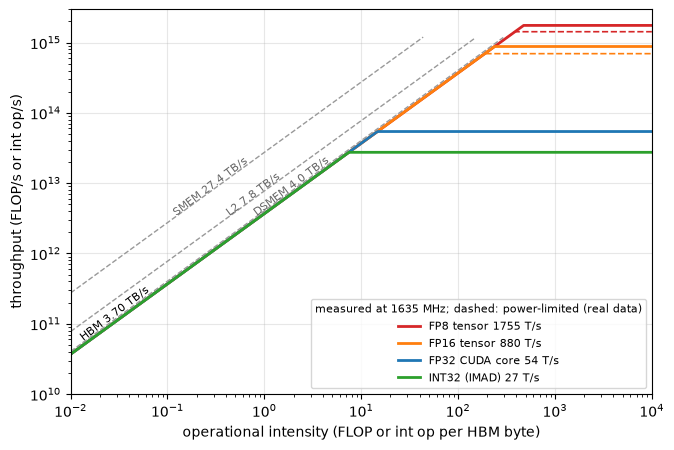

In [3]:
rf.fig_ceilings(C)

In [4]:
rf.table_ceilings(C)

,measured,unit,datasheet,peak at lock,measured / peak at lock,ridge vs HBM (op/B)
ceiling,,,,,,
FP8 tensor,1755.3,TFLOP/s,1670.5,1768.0,99%,474.5
BF16 tensor,879.2,TFLOP/s,835.5,884.0,99%,237.7
FP16 tensor,879.5,TFLOP/s,835.5,884.0,99%,237.8
FP32 CUDA core,54.3,TFLOP/s,60.0,55.2,98%,14.7
INT32 (IMAD),27.5,Tintop/s,—,27.6,99%,7.4
SMEM,27.4,TB/s,—,—,—,—
L2,7.8,TB/s,—,—,—,—
DSMEM,4.0,TB/s,—,—,—,—
HBM,3.7,TB/s,3.9,3.9,95%,—


**Compute.** Each compute ceiling is an instruction-throughput microbenchmark: FFMA and IMAD chains on every SM, and
back-to-back `wgmma` (operands in shared memory) for the tensor cores. They reach 98–99 % of the architectural rate at
the locked clock (256 FP32 FLOP, 4096 FP16/BF16 and 8192 FP8 tensor FLOP per SM per cycle): 54.3 TFLOP/s FP32, 879
TFLOP/s FP16/BF16 and 1755 TFLOP/s FP8. (The NVL datasheet quotes its tensor-core peaks at 1545 MHz, hence the lower
datasheet column.) Integer IMAD issues at half the FFMA rate (27.5 T op/s).

The tensor-core roofs hold only for operands that cost no power. With random fp16/bf16/fp8 operands the same wgmma
loops still issue at the full per-clock rate, but the card's 400 W limit pulls the SM clock from 1635 to 1300–1394 MHz
within every launch: 696 (FP16), 714 (BF16), 748 (FP16 accumulate) and 1428 TFLOP/s (FP8) is what dense tensor work on
real data can sustain here — the dashed roofs. Large library GEMMs show the same limit: cuBLAS at 8192³ reaches
479–536 TFLOP/s in FP16/BF16, and back-to-back launches drop the clock below the lock (61 of the first 100 launches).

**Memory.** HBM reaches 3.70 TB/s read (95 % of the 3.9 TB/s datasheet), L2 7.75 TB/s and shared memory 27.4 TB/s
(128 B per cycle per SM). These are the values microbench experiment 05 measured on GPU 2 of this server, within 1 %.

**DSMEM.** The table below is the aggregate bandwidth when every SM streams to or from a peer in its cluster, with
as many clusters as fit at one CTA per SM.

In [5]:
rf.table_dsmem(C)

,"pull (ld.shared::cluster.v4), TB/s","push (bulk copy), TB/s"
cluster size,,
2,3.54,4.04
4,2.77,3.24
8,2.78,2.93
16,2.59,2.49


The best case, bulk pushes in clusters of 2, reaches 4.04 TB/s, 88 % of the per-SM send limit of the SM-to-SM network
(21.33 B/cycle/SM × 132 SMs × 1.635 GHz = 4.6 TB/s, microbench experiment 11). Larger clusters lose up to 38 %, because
more of the traffic crosses the GPC's shared crossbar. The DSMEM ceiling is therefore only 9 % above the HBM
ceiling and 7× below shared memory: moving data between SMs is not a faster path than reading it from HBM. A DSMEM
port can gain on this roofline in one way only: by moving fewer bytes through HBM (higher intensity), or by replacing
a sequence of kernels whose intermediate results would otherwise make the round trip through memory.

## 2. CREDIT: six row-wise reductions in fp32

Each CREDIT workload processes a matrix row by row and needs one or two statistics of the whole row (a mean, a norm,
a maximum) before it can write the row's output. Three versions exist (`../workloads/credit_*.yaml`):

| role | kernel | how the row statistics are obtained |
|---|---|---|
| non-DSMEM | `block_*_read` | one CTA per row; the row is read from global memory again for every pass over it |
| control | `block_*_staged` | one CTA per row stages the whole row in its shared memory (only while the row fits in 227 KiB) |
| DSMEM | `cluster_*_staged` | a cluster of P CTAs splits the row; each stages its slice in shared memory and the partial statistics are all-reduced through DSMEM |

Rows are 4096, 16384 and 65536 floats (n4k, n16k, n64k), with 4096 rows (2048 for layernorm). P = 2, 4 and 8 were
measured; the marker of the DSMEM version is its fastest P. At 0.1–3.5 FLOP per HBM byte every point lies far left
of the FP32 ridge (14.7 FLOP/B): these kernels are bound by HBM, and the question is how many bytes each version
moves and how fast it moves them.

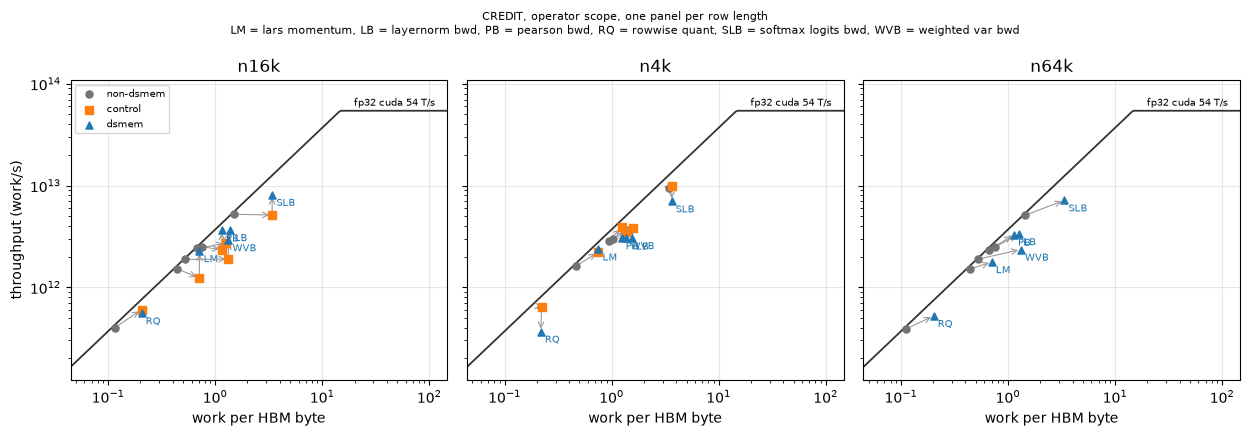

In [6]:
W = [w for w in L["M"] if w.startswith("credit")]
rf.fig_roofline(L, W, title="CREDIT, operator scope, one panel per row length")

In [7]:
rf.table_pairs(L, W)

**Long rows (n16k, n64k): DSMEM wins by reading every input once.** The DSMEM versions are 1.17–1.55× faster than
the one-CTA read kernels. Their HBM traffic is the compulsory traffic (0.96–1.05× of every array read or written once),
while the read kernels move 1.5–2.5× the compulsory bytes: once a row is longer than what the resident CTAs' rows can
keep in the 50 MB of L2, every extra pass over it goes back to HBM. On the roofline the DSMEM marker moves right, to
0.40–0.66× the bytes. The DSMEM traffic itself is negligible: at most 0.01 byte per HBM byte (one or two floats per
CTA per statistic), three orders of magnitude below what the 4.0 TB/s DSMEM ceiling could carry.

**But time falls less than bytes.** The read kernels stream at 3.3–3.6 TB/s (89–97 % of the HBM ceiling); the DSMEM
versions reach 1.8–3.2 TB/s, so they sit further below the HBM slope than the version they replace. The figure below
shows it directly: every pair lies above the diagonal, where a version that kept the read kernel's bandwidth would
sit. The one-CTA staged control loses bandwidth in the same way (1.4–3.0 TB/s at n16k), so the loss comes with staging
the row in shared memory, not with the cluster exchange; the profiles collected here do not identify the mechanism
(occupancy and stall reasons were not measured).

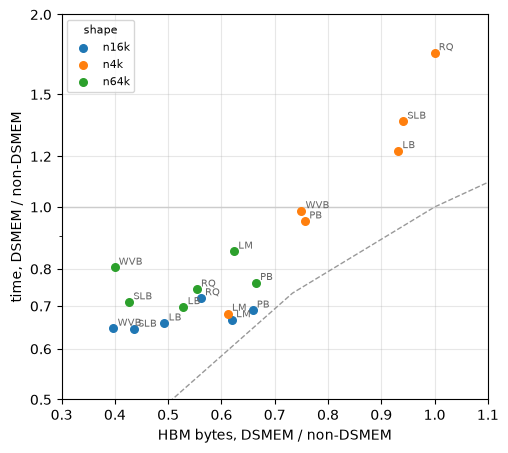

In [8]:
rf.fig_time_vs_bytes(L, W)

**Short rows (n4k): nothing to save.** A 16–48 KB row of the resident CTAs fits in L2, so the read kernel's
second pass hits L2 and it already moves close to the compulsory bytes (0.9–1.5×). The DSMEM version then only adds
cost: it is slower for layernorm, softmax and rowwise quantisation (0.57–0.82×), within 5 % for Pearson and weighted
variance, and faster only for LARS momentum (1.47×), whose three input arrays still overflow L2. Splitting a short
row over more CTAs also multiplies per-row work that every thread of every CTA repeats (precise divisions, block
reductions): for rowwise quantisation the ncu FP32 count reaches 2.25× the per-element formula at n4k with P = 2 and
6× with P = 8. This is why the best P is 2 at n4k, 2–8 at n16k and 8 at n64k.

In [9]:
rf.table_flop_check(L, W)

The table compares the ncu FP32 instruction count (2·FFMA + FADD + FMUL) of each marker with the manifest formula,
the per-element arithmetic as coded (identical in the three kernels). For the one-CTA kernels on long rows the counters
confirm the formula within 1–6 %; rowwise quantisation does 1 FP32 operation per element, so its per-row division alone
adds 16 % at n16k, and short rows add 12–63 %. The DSMEM kernels count 1–33 % more than the formula on long rows and up
to 2.25× on short ones: the per-row work above, done once per CTA, i.e. P times per row. The roofline uses the formula
(the work the computation requires), so this replicated work shows up as lower throughput, not as extra work.

## 3. DAK: TMA multicast of the weight tiles of a GEMM

DAK computes a linear layer C[tokens, M] = X · W in fp16 with fp16 accumulation (`../workloads/dak_gemm_multicast.yaml`).
The DSMEM version runs clusters of 2 CTAs that work on the two row halves of the same output tile: rank 0 loads each
8 KB weight tile once and multicasts it into the shared memory of both CTAs, rank 1 releases the buffer slot with a
remote mbarrier arrive. The non-DSMEM version is the same kernel without the cluster (each CTA loads the tile itself:
same tiles, warp roles and MMA). cuBLAS (`torch.mm`) is drawn as a reference. Shapes: the Llama-2-7B and OPT-30B
projections with 512 or 1024 tokens. Two races in the shipped multicast kernel (a missing barrier before the TMA store
of the output tile, and no cluster barrier before exit while the peer still arrives remotely, which made the kernel
fail under ncu) were fixed before measuring; the fix costs 0.5–2.5 % of its time (`../CLAUDE.md`, change log).

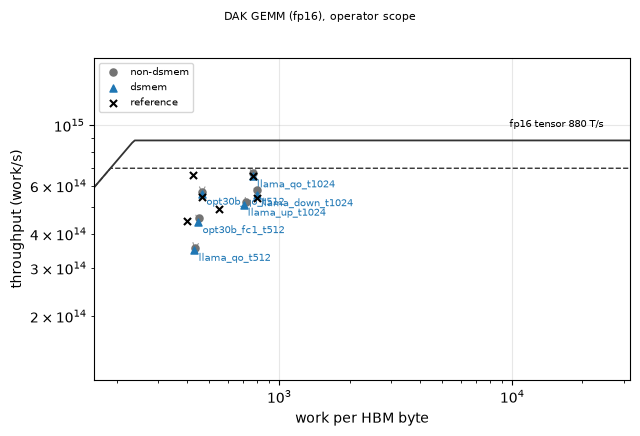

In [10]:
rf.fig_roofline(L, ["dak_gemm_multicast"], one_panel=True, title="DAK GEMM (fp16), operator scope")

In [11]:
rf.table_pairs(L, ["dak_gemm_multicast"])

At 430–800 FLOP per HBM byte every shape is a compute-bound GEMM, and both versions move exactly the compulsory
HBM bytes (0.95–1.07×): multicast cannot change the HBM intensity, and on this roofline the two markers coincide. Its
effect is one level up, between L2 and the SMs — and there it does not pay off either: the multicast version is
1–4 % slower than its twin at every shape. ncu attributes 67–822 MB per GEMM to multicast loads, yet reports 7–25 %
*more* total L2 bytes for the multicast kernel; how `lts__t_bytes` accounts for a multicast request is not settled
here. cuBLAS is 1.8× faster at the smallest shape (DAK's tiling leaves 68 of the 132 SMs idle at 512 × 4096 × 4096)
and 1–6 % slower at the others.

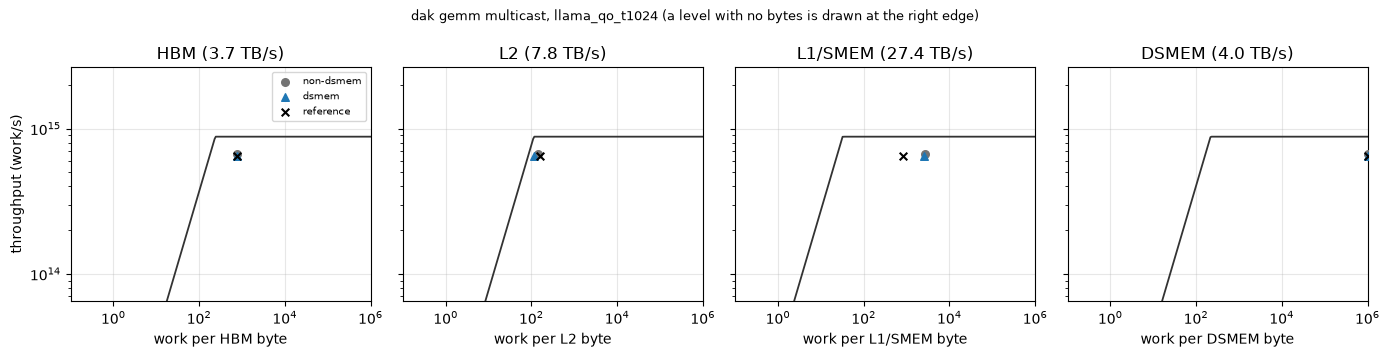

In [12]:
rf.fig_hierarchical(L, "dak_gemm_multicast", "llama_qo_t1024")

## 4. ClusterFusion: Llama-2-7B decoder attention block (and RMSNorm)

ClusterFusion fuses one decode step of a Llama-2-7B attention block into one kernel (`../workloads/clusterfusion_llama2_7b_decoder.yaml`):
RMSNorm, the QKV GEMV, RoPE, flash-decoding over the KV cache and the output projection, with 32 head clusters of 4 CTAs
that all-reduce partial GEMV results and attention statistics through DSMEM (bulk pushes and remote atomics). The
non-DSMEM version is the sequence it replaces, as in the artifact's own test: flashinfer RMSNorm, cuBLAS GEMV, torch
RoPE (12 small kernels), flashinfer single-token decode and cuBLAS GEMV — 18 kernels. The control is the same fused
kernel built with clusters of 1 (fusion without DSMEM, one CTA per head). Layer scope adds the FFN (merged gate/up GEMV,
SiLU·mul, down GEMV), the residual adds and the second RMSNorm to both.

The shipped kernel was not correct as called. Three races, all found by validating against the unfused sequence and
localising the corrupted elements, were fixed before any timing: (1) all 32 head clusters read `residual` and wrote
`input + residual` back into it, so a cluster that read late normalised the wrong vector (fixed by writing to a separate
output, as the artifact's own batch kernel does); (2) in the GEMV and decode loops one thread refills a TMA buffer
that the other warps may still be reading (one block barrier per loop; at cluster size 4, 34 of 200 launches had a
corrupted head before the fix, 0 of 600 after); (3) the DSMEM all-reduce added into its send buffer before its own
outgoing bulk copy had provably finished reading it (a cluster barrier per round, required by the PTX memory model,
never observed to fail). The cluster-1 control also needed an RMSNorm fix (the prologue kept only one of four chunks).
The fixes add about 1–3 % to the fused kernel's time (`../CLAUDE.md`, change log).

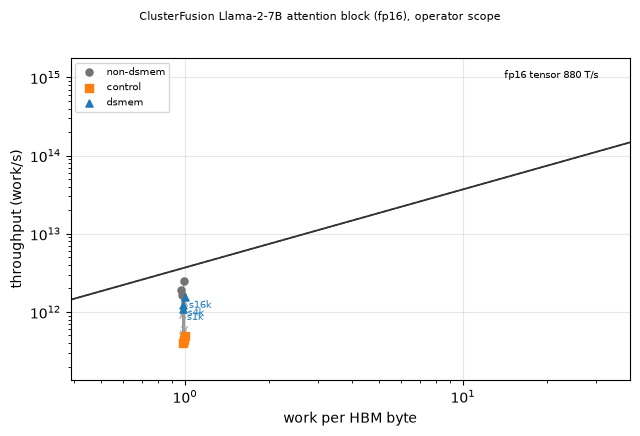

In [13]:
rf.fig_roofline(L, ["clusterfusion_llama2_7b_decoder"], one_panel=True, title="ClusterFusion Llama-2-7B attention block (fp16), operator scope")

In [14]:
rf.table_pairs(L, ["clusterfusion_llama2_7b_decoder"])

All three versions move the same bytes — the 128 MB of attention weights and the KV cache, i.e. the compulsory
traffic (1.00–1.02×): a decode step's intermediates are a few KB, so fusing them saves no HBM traffic, and on the
roofline the markers sit at the same intensity (1 FLOP per byte, far left of every ridge). What differs is how fast the
bytes stream in. The unfused kernels reach 1.7–2.5 TB/s, the fused DSMEM kernel 1.1–1.6 TB/s and the cluster-1 control
0.4–0.5 TB/s, so the fused kernel is **0.63–0.66× the speed** of the sequence it replaces in kernel time: 128 CTAs
(one 4-CTA cluster per head) cannot stream a GEMV's weights as fast as cuBLAS's GEMV over all 132 SMs, and the
cluster-1 control, with 32 CTAs, shows how much worse it is without splitting heads across SMs.

Kernel time excludes the gaps between the 18 launches, which is what fusion removes as well. Measured from the first
kernel's start to the last kernel's end, the unfused sequence takes 207–234 µs when launched eagerly from Python (an
upper bound: CUDA graphs would shrink the gaps); against that the fused kernel is 1.68× faster at 1k tokens, 1.28× at
4k and 0.91× at 16k. At layer scope the FFN is identical in both versions, and the attention block is 50–64 % of the
unfused layer's kernel time: the fused layer is 0.72–0.79× the unfused layer in kernel time.

ClusterFusion's RMSNorm (batch 64 × 8192, cluster of 2 with one remote atomic per row) is 0.82× flashinfer's
(3.78 vs 3.10 µs); the 1 MB output stays in L2, so ncu sees only the input read.

In [15]:
rf.table_pairs(L, ["clusterfusion_rmsnorm"])

,,non-DSMEM µs,control µs,DSMEM µs,best P,speedup vs non-DSMEM,HBM bytes DSMEM / non-DSMEM,HBM bytes DSMEM / compulsory,HBM TB/s non-DSMEM,HBM TB/s DSMEM,DSMEM / HBM bytes
workload,shape,,,,,,,,,,
clusterfusion rmsnorm,s0,3.1,—,3.8,2,0.82,1.00,0.51,0.35,0.29,0.011


## 5. DeepGEMM: FP8 GEMM with TMA multicast

DeepGEMM's SM90 FP8 GEMM (e4m3 inputs with 1×128 and 128×128 block scales, bf16 output) picks a cluster of 2 with
multicast of the A or B tile whenever the grid has more than one wave (`../workloads/deepgemm_fp8_gemm_multicast.yaml`).
The non-DSMEM version is the same JIT kernel with the cluster forced to 1 (a two-line heuristic patch); the printed
configurations show identical block sizes, pipeline stages and waves, so the two differ only in multicast.
cuBLASLt's FP8 GEMM is drawn as a reference — and launches 1×2 / 2×1 cluster kernels with multicast itself (ncu:
0.47–4.3 GB of multicast loads). Shapes: four DeepSeek-V3 projections with 4096 tokens and a grouped MoE GEMM
(8 experts × 4096 tokens).

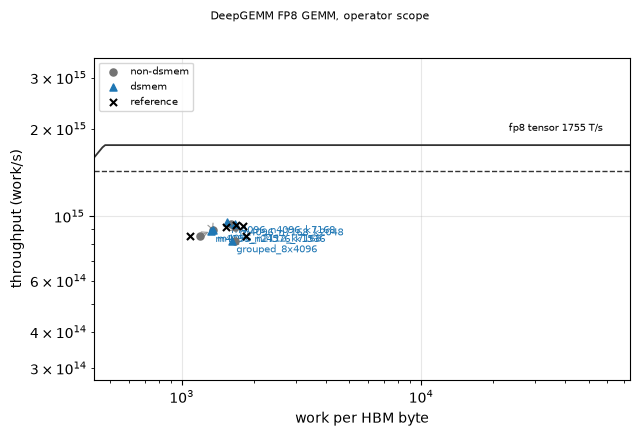

In [16]:
rf.fig_roofline(L, ["deepgemm_fp8_gemm_multicast"], one_panel=True, title="DeepGEMM FP8 GEMM, operator scope")

In [17]:
rf.table_pairs(L, ["deepgemm_fp8_gemm_multicast"])

All shapes sit deep in the compute-bound region (1300–1700 FLOP per HBM byte; 818–955 TFLOP/s). Multicast changes
the time by −0.4 % to +3.8 %: the largest gain is the 24-wave shape (N = 24576, K = 1536), where it also cuts HBM
bytes by 10 % and L2 bytes by 9 %; at the other shapes L2 bytes drop by 6–12 % (N = 2112: +0.5 %) and HBM bytes stay
within ±3.5 %.
With a K loop of 1536–7168 per tile, the tensor cores, not the operand traffic, set the time; halving one operand's
L2 reads therefore saves little. HBM bytes are 1.25–1.67× the compulsory traffic at three shapes (operands re-read
from HBM across waves) and 0.88–0.95× at two (part of the output still in L2 when the kernel ends).

## 6. hpc-ops: exact top-2048 with a cluster of 8

The top-k kernel selects the 2048 largest of n fp32 logits per row by a two-pass radix select
(`../workloads/hpcops_topk_cluster8.yaml`); work is counted in integer operations (key conversion, histogram updates,
compares), so its roof is the IMAD ceiling. With few rows (m ≤ 16) and long rows (n ≥ 32768) the library splits each
row over a cluster of 8 CTAs that combine their histograms and candidate counts through DSMEM. Without the cluster
(the library's own dispatch on pre-Hopper GPUs, obtained with a one-line patch) each row is processed by one CTA, or,
at n = 240k, by an 8-way split that exchanges through global memory. The Lamport RMSNorm of hpc-ops is a multi-GPU
kernel (it waits for a multicast broadcast from the other ranks and the library rejects one rank) and is not
measurable on one GPU.

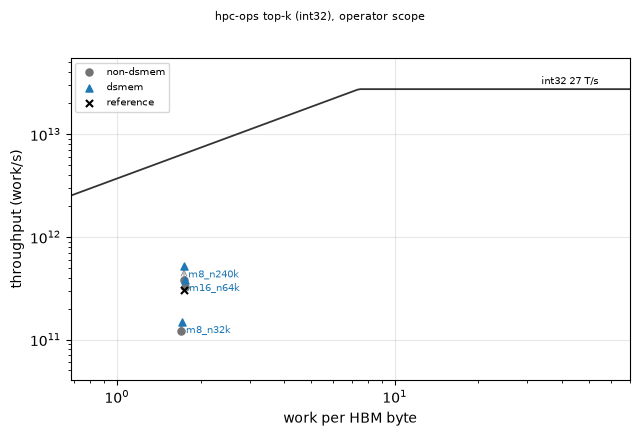

In [18]:
rf.fig_roofline(L, ["hpcops_topk_cluster8"], one_panel=True, title="hpc-ops top-k (int32), operator scope")

In [19]:
rf.table_pairs(L, ["hpcops_topk_cluster8"])

The cluster version is 1.18–1.37× faster. Both versions read exactly the compulsory bytes, yet none is anywhere
near a roof: 1–8 MB in 13–37 µs is 2–8 % of the HBM bandwidth, and the integer throughput is far below the IMAD
ceiling. With 8 or 16 rows, one CTA per row occupies 8–16 of the 132 SMs; a cluster of 8 per row uses 64–128. The gain
is parallelism, and DSMEM is what makes splitting a row cheap: here the DSMEM traffic (1.9–3.7 MB) is as large as the
HBM traffic, the only workload in this study where that is so. The global-memory split at n = 240k is the slowest
way to use the same SMs (1.37× slower than the cluster).

## 7. ClusterFusion: DeepSeek-V2-Lite MLA decode

The fused kernel runs one decode step of DeepSeek-V2-Lite's multi-head latent attention in one launch: RMSNorm, the
q / kv down-projections, the latent RMSNorm, the absorbed W_UK product, flash-decoding over the 512-wide latent
cache (4096 tokens), W_UV and the output projection, with 16 head clusters of 4 CTAs that reduce partial results
through DSMEM (`../workloads/clusterfusion_deepseek_v2_lite_mla.yaml`). As shipped it omits the RoPE term of the score
and does not append the new token to the cache; the unfused baseline (10 kernels: flashinfer RMSNorm, RoPE and decode,
cuBLAS GEMVs, batched products for the absorbed weights) computes exactly the same function. The cluster-1 control
needed three upstream fixes (shared-memory slices hard-coded for cluster 4). The kernel has the same race patterns as
the Llama kernel (TMA buffer refills, the DSMEM all-reduce, plus in-place writes to a shared buffer other warps still
read); none was observed to fail here, but they are fixed the same way for both builds. The unpatched kernel
validated and ran 223.5 µs, the fixed one 226.6 µs.

In [20]:
rf.table_pairs(L, ["clusterfusion_deepseek_v2_lite_mla"])

,,non-DSMEM µs,control µs,DSMEM µs,best P,speedup vs non-DSMEM,HBM bytes DSMEM / non-DSMEM,HBM bytes DSMEM / compulsory,HBM TB/s non-DSMEM,HBM TB/s DSMEM,DSMEM / HBM bytes
workload,shape,,,,,,,,,,
clusterfusion deepseek v2 lite mla,s4k,139.4,717.2,226.6,4,0.62,1.02,1.03,0.23,0.14,0.017


The fused DSMEM kernel is slower than the unfused sequence (226.6 vs 139.4 µs, 0.62×); the cluster-1 control takes
717 µs. All three move the same 32 MB from HBM — the weights and the latent cache, i.e. the compulsory traffic: the
intermediates of an MLA decode step are a few KB per head, so fusing them removes no HBM traffic. What remains is how
fast the 32 MB stream in: the unfused GEMVs and decode kernels reach 0.23 TB/s, the fused kernel 0.15 TB/s, each far
below the HBM ceiling because a single token gives each kernel little parallelism (the fused kernel runs 64 CTAs,
through serial GEMV phases separated by cluster reductions).